Example state data: [(0.0, 1), (0.6079988032651082, 0), (1.6058390470354196, 1), (2.440827184534235, 0), (2.487847377385198, 1)]


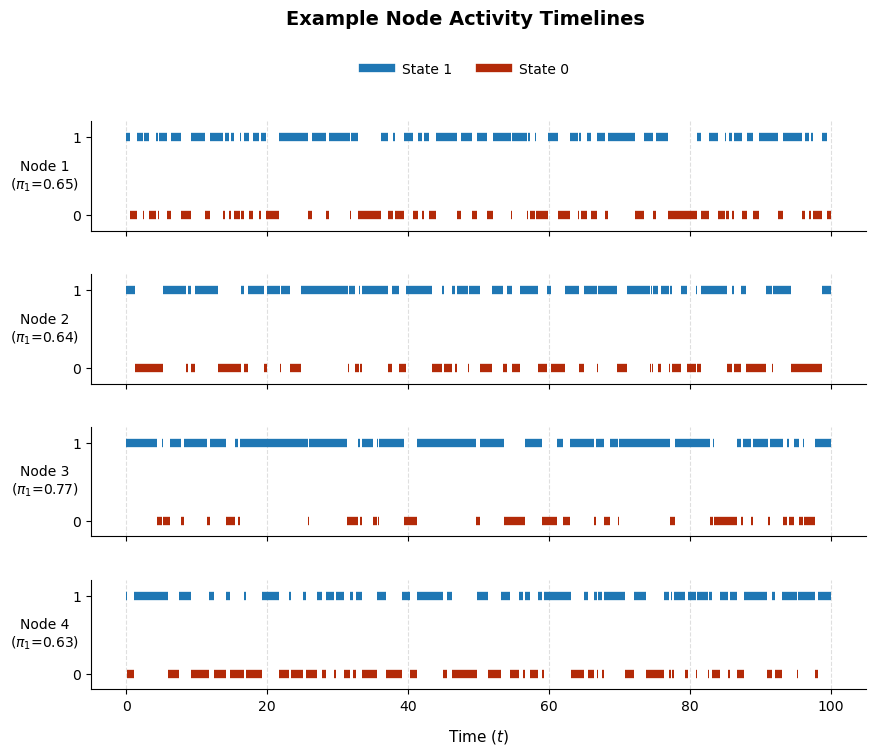

In [20]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
from markov_chains import ContinuousTimeMarkov

# Generate parameters and calculate steady-state probabilities
np.random.seed(123)
params = np.array([np.random.normal(40, 5, size=4), np.random.normal(20, 3, size=4)])
probs = params[0] / (params[0] + params[1])  # Target steady-state probs for State 1
# Run simulation
ctmc = ContinuousTimeMarkov(probs=probs, max_time=100.0)
states = ctmc.simulate()
print(f'Example state data: {states[0][:5]}')
df = ctmc.event_list_to_df(states)
ctmc.plot(states, title='Example Node Activity Timelines')

In [21]:
print(df.head(10))

     node      time  state
0  node_1  0.000000      1
1  node_2  0.000000      1
2  node_3  0.000000      1
3  node_4  0.000000      1
4  node_4  0.064249      0
5  node_1  0.607999      0
6  node_4  1.042630      1
7  node_2  1.210875      0
8  node_1  1.605839      1
9  node_2  1.783914      1


In [22]:
# Marginal PDF 
marginal = pd.crosstab(df["node"], df["state"], normalize="index")
print(f"Marginal PDF: \n{marginal}")

Marginal PDF: 
state          0         1
node                      
node_1  0.504673  0.495327
node_2  0.488889  0.511111
node_3  0.487500  0.512500
node_4  0.489583  0.510417


In [23]:
class TimelineAnalysis: 

    def __init__(self, df, horizon=None, nodes=None):
        self.events = df.copy()
        self.events["time"] = pd.to_numeric(self.events["time"])
        self.events["state"] = pd.to_numeric(self.events["state"])
        self.events = self.events.drop_duplicates(subset=["node", "time", "state"]).reset_index(drop=True)
        self.nodes = (sorted(self.events["node"].unique()) if nodes is None else list(nodes))
        # Default to one time unit beyond the last event.
        self.horizon = (float(self.events["time"].max()) + 1.0 if horizon is None else float(horizon))
        if self.horizon <= self.events["time"].max():
            raise ValueError("horizon must exceed the final event time.")
        self.intervals = self._get_intervals()
        self.occupancy_df = self._get_occupancy()
        self.transition_events_df = self.transition_events
        self.transition_summary_df = self._get_transition_summary()
        self.conditional_transitions_df = self._get_conditional_transitions()

    def _get_intervals(self):
        events = self.events.sort_values("time", kind="stable")
        initial = events[events["time"] == 0]
        if set(initial["node"]) != set(self.nodes):
            raise ValueError("Each node must have an initial state at time 0.")
        if initial["node"].duplicated().any():
            raise ValueError("Each node must have exactly one initial state.")
        state = initial.set_index("node")["state"].astype(int).to_dict()
        intervals = []
        transition_events = []
        previous_time = 0.0
        for time, group in events[events["time"] > 0].groupby("time", sort=True):
            time = float(time)
            # Record the state that persists up to this event time.
            if time > previous_time:
                intervals.append({"start": previous_time, "end": time, "duration": time - previous_time, **state.copy(),})
            # Apply all observations at the event time.
            for node, node_group in group.groupby("node", sort=False):
                values = node_group["state"].astype(int).unique()
                if len(values) != 1:
                    raise ValueError(f"Conflicting states for {node} at time {time}.")
                new_state = int(values[0])
                old_state = int(state[node])
                if new_state != old_state:
                    transition_events.append({
                        "time": time,
                        "node": node,
                        "from_state": old_state,
                        "to_state": new_state,
                        "direction": f"{old_state}_to_{new_state}",
                        **{f"context_{other}": int(state[other]) for other in self.nodes if other != node},
                    })
                state[node] = new_state
            previous_time = time
        # Append the final interval exactly once.
        if self.horizon > previous_time:
            intervals.append({"start": previous_time, "end": self.horizon, "duration": self.horizon - previous_time, **state.copy(),})
        self.transition_events = pd.DataFrame(transition_events)
        return pd.DataFrame(intervals)

    def _get_occupancy(self):
        """ Joint occupancy from time-weighted intervals. """
        occupancy = (self.intervals.groupby(self.nodes, as_index=False)["duration"].sum().rename(columns={"duration": "time_in_state"}))
        occupancy["probability"] = occupancy["time_in_state"] / self.horizon
        return occupancy.sort_values("probability", ascending=False).reset_index(drop=True)        

    def _get_transition_summary(self):
        # Per-node exposure time and transition counts.
        summary = []
        for node in self.nodes:
            active_time = self.intervals.loc[self.intervals[node] == 1, "duration"].sum()
            inactive_time = self.intervals.loc[self.intervals[node] == 0, "duration"].sum()
            if self.transition_events.empty:
                node_events = pd.DataFrame()
            else:
                node_events = self.transition_events[self.transition_events["node"] == node]
            n01 = ((node_events["direction"] == "0_to_1").sum() if not node_events.empty else 0)
            n10 = ((node_events["direction"] == "1_to_0").sum() if not node_events.empty else 0)
            summary.append({
                "node": node,
                "active_time": active_time,
                "inactive_time": inactive_time,
                "P_active": active_time / self.horizon,
                "n_01": int(n01),
                "n_10": int(n10),
                "q_01": n01 / inactive_time if inactive_time > 0 else np.nan,
                "q_10": n10 / active_time if active_time > 0 else np.nan,
            })
        return pd.DataFrame(summary)

    def _get_conditional_transitions(self):
        """Conditional transition rates given another node's pre-event state."""
        conditional_rows = []
        for target in self.nodes:
            for context in self.nodes:
                if target == context:
                    continue
                context_col = f"context_{context}"
                for context_state in (0, 1):
                    # 1 -> 0: target is active and then becomes inactive.
                    active_exposure = self.intervals.loc[(self.intervals[target] == 1) & (self.intervals[context] == context_state), "duration",].sum()
                    n10 = (
                        (self.transition_events["node"] == target)
                        & (self.transition_events["direction"] == "1_to_0")
                        & (self.transition_events[context_col] == context_state)
                    ).sum()
                    conditional_rows.append({
                        "target": target,
                        "context": context,
                        "context_state": context_state,
                        "transition_type": "1_to_0",
                        "exposure_time": active_exposure,
                        "transition_count": int(n10),
                        "transition_rate": (n10 / active_exposure if active_exposure > 0 else np.nan),
                    })
                    # 0 -> 1: target is inactive and then becomes active.
                    inactive_exposure = self.intervals.loc[(self.intervals[target] == 0) & (self.intervals[context] == context_state), "duration",].sum()
                    n01 = (
                        (self.transition_events["node"] == target)
                        & (self.transition_events["direction"] == "0_to_1")
                        & (self.transition_events[context_col] == context_state)
                    ).sum()
                    conditional_rows.append({
                        "target": target,
                        "context": context,
                        "context_state": context_state,
                        "transition_type": "0_to_1",
                        "exposure_time": inactive_exposure,
                        "transition_count": int(n01),
                        "transition_rate": (n01 / inactive_exposure if inactive_exposure > 0 else np.nan),
                    })
        return pd.DataFrame(conditional_rows)

In [24]:
print(
    df.loc[df["time"].eq(0)]
      .sort_values(["node", "time"])
      .to_string(index=False)
)

  node  time  state
node_1   0.0      1
node_2   0.0      1
node_3   0.0      1
node_4   0.0      1


In [25]:
tla = TimelineAnalysis(df)

In [26]:
print(list(tla.intervals.columns))
print(list(tla.occupancy_df.columns))
print(list(tla.transition_summary_df.columns))
print(list(tla.conditional_transitions_df.columns))


['start', 'end', 'duration', 'node_1', 'node_2', 'node_3', 'node_4']
['node_1', 'node_2', 'node_3', 'node_4', 'time_in_state', 'probability']
['node', 'active_time', 'inactive_time', 'P_active', 'n_01', 'n_10', 'q_01', 'q_10']
['target', 'context', 'context_state', 'transition_type', 'exposure_time', 'transition_count', 'transition_rate']


In [27]:

class UncertaintyAnalysis:
    """
    Moving-block bootstrap uncertainty analysis for a piecewise-constant, multivariate binary-state trajectory.
    Paper: https://arxiv.org/pdf/0711.4493
    
    block_length : float
        Resampling block length in the same units as event times.
    n_bootstrap : int
        Number of bootstrap replicates.
    confidence : float
        Confidence level, e.g. 0.95.
    pairs : list[tuple], optional
        Target/context pairs to analyze. If None, all directed pairs are analyzed for conditional transition rates.
    """

    def __init__(self, tla, block_length, n_bootstrap=1000, confidence=0.95, seed=123, pairs=None,):
        self.tla = tla
        self.nodes = list(tla.nodes)
        self.horizon = float(tla.horizon)
        self.block_length = float(block_length)
        self.n_bootstrap = int(n_bootstrap)
        self.confidence = float(confidence)
        self.rng = np.random.default_rng(seed)
        self.intervals = tla.intervals.copy()
        self.events = tla.transition_events.copy()
        if pairs is None:
            self.pairs = [(target, context) for target in self.nodes for context in self.nodes if target != context]
        else:
            self.pairs = list(pairs)
        self._init_vectorized()
        self._validate_events()
        
        self.bootstrap_samples = None
        self.summary = None
        self.point_estimates = None

    def _init_vectorized(self):
        self._starts = self.intervals["start"].to_numpy(dtype=float)
        self._ends = self.intervals["end"].to_numpy(dtype=float)
        self._durations = self.intervals["duration"].to_numpy(dtype=float)
        self._X = self.intervals[self.nodes].to_numpy(dtype=np.int8)
        self._event_times = self.events["time"].to_numpy(dtype=float)
        self._event_nodes = self.events["node"].to_numpy()
        self._event_directions = self.events["direction"].to_numpy()
        self._node_idx = {node: i for i, node in enumerate(self.nodes)}
        self._node_event_idx = np.array([self._node_idx.get(node, -1) for node in self._event_nodes], dtype=np.int32,)
        self._direction_idx = np.where(self._event_directions == "0_to_1", 0, 1)
        self._context_states = {}

        for context in self.nodes:
            values = np.full(len(self.events), np.nan, dtype=float)
            if len(self.events):
                event_times = self._event_times
                # Find the interval containing each event time immediately before the event. Intervals are [start, end).
                idx = np.searchsorted(self._starts, self._event_times, side="right") - 1
                valid = ((idx >= 0) & (idx < len(self._X)) & (self._event_times <= self._ends[np.clip(idx, 0, len(self._ends) - 1)]))
                # Use the interval state for each event.
                values[valid] = self._X[idx[valid], self._node_idx[context]]
            self._context_states[context] = values
            


    def _validate_events(self):
        """Validate interval and transition-event data."""
        required_interval_cols = {"start", "end", "duration", *self.nodes}
        missing_intervals = required_interval_cols - set(self.intervals.columns)
        if missing_intervals:
            raise ValueError(f"Missing interval columns: {sorted(missing_intervals)}")
        if not 0 < self.block_length < self.horizon:
            raise ValueError("block_length must be positive and less than the horizon.")
        if self.n_bootstrap < 1:
            raise ValueError("n_bootstrap must be positive.")
        if not 0 < self.confidence < 1:
            raise ValueError("confidence must be between 0 and 1.")
        required_event_cols = {"time", "node", "direction"}
        if self.events.empty:
            self.events = pd.DataFrame(columns=["time", "node", "direction", *[f"context_{n}" for n in self.nodes],])
        else:
            missing_events = required_event_cols - set(self.events.columns)
            if missing_events:
                raise ValueError(f"Missing transition-event columns: {sorted(missing_events)}")
            self.events["time"] = pd.to_numeric(self.events["time"], errors="raise")
            if not self.events["time"].is_monotonic_increasing:
                self.events = self.events.sort_values("time", kind="stable").reset_index(drop=True)
        valid_directions = {"0_to_1", "1_to_0"}
        invalid = set(self.events["direction"].dropna()) - valid_directions
        if invalid:
            raise ValueError(f"Unexpected transition directions: {invalid}")
        for target, context in self.pairs:
            if target not in self.nodes or context not in self.nodes:
                raise ValueError(f"Unknown node in pair {(target, context)}")
            if target == context:
                raise ValueError("Target and context must differ.")
            col = f"context_{context}"
            if col not in self.events.columns:
                raise ValueError(f"Missing pre-event context column {col!r}. Check how tlAnalysis creates transition events.")
                               
    def _sample_blocks(self):
        """Sample fixed-duration time windows covering one horizon."""
        blocks = []
        remaining = self.horizon
        while remaining > 1e-12:
            length = min(self.block_length, remaining)
            max_start = self.horizon - length
            start = (self.rng.uniform(0.0, max_start) if max_start > 1e-12 else 0.0)
            end = start + length
            blocks.append((start, end))
            remaining -= length
        return blocks

    def _calculate_statistics(self, blocks):
        """Vectorized statistics for sampled time blocks."""
        p = len(self.nodes)
        horizon = sum(b - a for a, b in blocks)
        # Exposure by node and state.
        exposure = np.zeros((p, 2), dtype=float)
        # Pairwise joint active exposure.
        joint = np.zeros((p, p), dtype=float)
        # Conditional exposure: target, context, target state, context state.
        cond_exp = {pair: np.zeros((2, 2), dtype=float) for pair in self.pairs}
        # Transition counts by node and direction (0->1, 1->0).
        counts = np.zeros((p, 2), dtype=np.int64)

        # Conditional counts indexed by (target, context, context_state, direction), where direction index 0=0->1, 1=1->0.
        cond_counts = {pair: np.zeros((2, 2), dtype=np.int64) for pair in self.pairs}
        X = self._X
        starts = self._starts
        ends = self._ends
        for a, b in blocks:
            # Intersect all observed intervals with the sampled block.
            d= np.maximum(0.0, np.minimum(ends, b) - np.maximum(starts, a),)
            keep = d > 0
            if not np.any(keep):
                continue
            x = X[keep]
            w = d[keep]
            # Vectorized state exposure.
            active_time = w @ x
            exposure[:, 1] += active_time
            exposure[:, 0] += w.sum() - active_time
            # Joint active time for all node pairs.
            joint += x.T @ (w[:, None] * x)
            # Conditional exposure for requested pairs.
            for target, context in self.pairs:
                ti = self._node_idx[target]
                ci = self._node_idx[context]
                # Accumulate all four state combinations.
                for ts in (0, 1):
                    for cs in (0, 1):
                        mask = (x[:, ti] == ts) & (x[:, ci] == cs)
                        cond_exp[(target, context)][ts, cs] += w[mask].sum()
            # Binary search identifies events strictly inside the block.
            lo = np.searchsorted(self._event_times, a, side="right")
            hi = np.searchsorted(self._event_times, b, side="left")
            if hi <= lo:
                continue
            event_idx = np.arange(lo, hi)
            valid = self._node_event_idx[event_idx] >= 0
            event_idx = event_idx[valid]
            if len(event_idx) == 0:
                continue
            node_ids = self._node_event_idx[event_idx]
            dir_ids = self._direction_idx[event_idx]
            np.add.at(counts, (node_ids, dir_ids), 1)
            # Conditional event counts, excluding unknown context states.
            for target, context in self.pairs:
                ti = self._node_idx[target]
                target_mask = self._node_event_idx[event_idx] == ti
                if not np.any(target_mask):
                    continue
                selected = event_idx[target_mask]
                context_states = self._context_states[context][selected]
                dirs = self._direction_idx[selected]
                # Only 0 and 1 are valid context-state indices.
                valid = np.isin(context_states, [0, 1])
                if not np.any(valid):
                    continue
                context_states = context_states[valid].astype(np.intp)
                dirs = dirs[valid]
                np.add.at(cond_counts[(target, context)], (context_states, dirs), 1,)
        rows = []
        # Node activity probabilities.
        for i, node in enumerate(self.nodes):
            rows.append({
                "metric": "active_probability",
                "node": node,
                "target": None,
                "context": None,
                "context_state": None,
                "transition_type": None,
                "estimate": exposure[i, 1] / horizon,
            })
        # Pairwise joint activity probabilities; each unordered pair once.
        for i, a in enumerate(self.nodes):
            for j in range(i + 1, p):
                b = self.nodes[j]
                rows.append({
                    "metric": "joint_active_probability",
                    "node": None,
                    "target": a,
                    "context": b,
                    "context_state": None,
                    "transition_type": None,
                    "estimate": joint[i, j] / horizon,
                })
        # Unconditional transition rates.
        for i, node in enumerate(self.nodes):
            for direction_idx, direction in enumerate(("0_to_1", "1_to_0")):
                source_state = direction_idx
                denominator = exposure[i, source_state]
                n = counts[i, direction_idx]
                rows.append({
                    "metric": "transition_rate",
                    "node": node,
                    "target": node,
                    "context": None,
                    "context_state": None,
                    "transition_type": direction,
                    "estimate": n / denominator if denominator > 0 else np.nan,
                })
        # Conditional transition rates.
        for target, context in self.pairs:
            for cs in (0, 1):
                for direction_idx, direction in enumerate(("0_to_1", "1_to_0")):
                    source_state = 1 - direction_idx
                    denominator = cond_exp[(target, context)][source_state, cs]
                    n = cond_counts[(target, context)][cs, direction_idx]
                    rows.append({
                        "metric": "conditional_transition_rate",
                        "node": None,
                        "target": target,
                        "context": context,
                        "context_state": cs,
                        "transition_type": direction,
                        "estimate": n / denominator if denominator > 0 else np.nan,
                    })
        return pd.DataFrame(rows)


    def _split_summary(self, summary):
        """Convert the long-form summary into metric-specific DataFrames."""
        specs = {
            "active_probability": {"keys": ["node"],},
            "joint_active_probability": {"keys": ["node_i", "node_j"],},
            "transition_rate": {"keys": ["node", "transition_type"],},
            "conditional_transition_rate": {"keys": ["target", "context", "context_state", "transition_type"],},
        }
        outputs = {}
        for metric, spec in specs.items():
            keys = spec["keys"]
            frame = summary.loc[summary["metric"].eq(metric)].copy()
            # Rename joint-pair identifiers to meaningful column names.
            if metric == "joint_active_probability":
                frame = frame.rename(columns={"target": "node_i", "context": "node_j"})
            columns = keys + ["estimate", "bootstrap_se", "lower", "upper", "valid_replicates", "n_bootstrap",]
            outputs[metric] = frame.loc[:, columns].reset_index(drop=True)
        return outputs

    def fit(self):
        """Run bootstrap replicates and return percentile intervals."""
        full_window = [(0.0, self.horizon)]
        self.point_estimates = self._calculate_statistics(full_window)
        bootstrap_results = []
        for replicate in range(self.n_bootstrap):
            blocks = self._sample_blocks()
            result = self._calculate_statistics(blocks)
            result["replicate"] = replicate
            bootstrap_results.append(result)
        self.bootstrap_samples = pd.concat(bootstrap_results, ignore_index=True)
        keys = ["metric", "node", "target", "context", "context_state", "transition_type",]
        alpha = 1.0 - self.confidence
        summary_rows = []
        grouped = self.bootstrap_samples.groupby(keys, dropna=False, sort=False)
        for key, group in grouped:
            values = group["estimate"].dropna().to_numpy()
            point_mask = np.ones(len(self.point_estimates), dtype=bool)
            for col, value in zip(keys, key):
                if pd.isna(value):
                    point_mask &= self.point_estimates[col].isna()
                else:
                    point_mask &= (self.point_estimates[col] == value).to_numpy()
            point_values = self.point_estimates.loc[point_mask, "estimate"]
            point = (float(point_values.iloc[0]) if len(point_values) else np.nan)
            if len(values):
                lower, upper = np.quantile(values, [alpha / 2, 1 - alpha / 2])
                se = np.std(values, ddof=1) if len(values) > 1 else np.nan
            else:
                lower = upper = se = np.nan
            row = dict(zip(keys, key))
            row.update({
                "estimate": point,
                "bootstrap_se": se,
                "lower": lower,
                "upper": upper,
                "valid_replicates": len(values),
                "n_bootstrap": self.n_bootstrap,
            })
            summary_rows.append(row)
        self.long_summary = pd.DataFrame(summary_rows)
        self.summary = self._split_summary(self.long_summary)
        return self.summary

    def conditional_rate_differences(self):
        """
        Bootstrap intervals for the difference in conditional rates:
        rate(context=1) - rate(context=0).
        """
        if self.bootstrap_samples is None:
            raise RuntimeError("Call fit() before requesting differences.")
        keys = ["target", "context", "transition_type"]
        data = self.bootstrap_samples.loc[self.bootstrap_samples["metric"] == "conditional_transition_rate"]
        wide= data.pivot_table(index=["replicate", *keys], columns="context_state", values="estimate", aggfunc="first",).reset_index()
        if 0 not in wide.columns or 1 not in wide.columns:
            raise ValueError("Insufficient bootstrap results for both states.")
        wide["difference"] = wide[1] - wide[0]
        alpha = 1.0 - self.confidence
        rows = []
        for key, group in wide.groupby(keys, dropna=False):
            values = group["difference"].dropna().to_numpy()
            point_data = self.point_estimates.loc[self.point_estimates["metric"] == "conditional_transition_rate"]
            target, context, direction = key
            point0 = point_data.loc[
                (point_data["target"] == target)
                & (point_data["context"] == context)
                & (point_data["context_state"] == 0)
                & (point_data["transition_type"] == direction),
                "estimate",
            ]
            point1 = point_data.loc[
                (point_data["target"] == target)
                & (point_data["context"] == context)
                & (point_data["context_state"] == 1)
                & (point_data["transition_type"] == direction),
                "estimate",
            ]
            estimate = (
                float(point1.iloc[0] - point0.iloc[0])
                if len(point0) and len(point1)
                and np.isfinite(point0.iloc[0])
                and np.isfinite(point1.iloc[0])
                else np.nan
            )
            rows.append({
                "target": target,
                "context": context,
                "transition_type": direction,
                "rate_difference": estimate,
                "lower": (np.quantile(values, alpha / 2) if len(values) else np.nan),
                "upper": (np.quantile(values, 1 - alpha / 2) if len(values) else np.nan),
                "bootstrap_se": (np.std(values, ddof=1) if len(values) > 1 else np.nan),
                "valid_replicates": len(values),
            })
        return pd.DataFrame(rows)

    


In [28]:
import warnings
warnings.filterwarnings("error", message="invalid value encountered in cast", category=RuntimeWarning,)
uncertainty = UncertaintyAnalysis(tla, block_length=5.0, n_bootstrap=1000, confidence=0.95, seed=123,)
uncertainty_summary = uncertainty.fit()
df_activity = uncertainty_summary["active_probability"]
df_joint = uncertainty_summary["joint_active_probability"]
df_rates = uncertainty_summary["transition_rate"]
df_conditional = uncertainty_summary["conditional_transition_rate"]

In [29]:
events = tla.transition_events

print(events[["time", "node", "direction", "context_node_4"]].head(20))

print("\nTransitions by node:")
print(events["node"].value_counts(dropna=False))

print("\nMissing context values:")
print(events.filter(like="context_").isna().sum())

        time    node direction  context_node_4
0   0.064249  node_4    1_to_0             NaN
1   0.607999  node_1    1_to_0             0.0
2   1.042630  node_4    0_to_1             NaN
3   1.210875  node_2    1_to_0             1.0
4   1.605839  node_1    0_to_1             1.0
5   1.783914  node_2    0_to_1             1.0
6   1.787686  node_2    1_to_0             1.0
7   1.814684  node_3    1_to_0             1.0
8   1.885461  node_3    0_to_1             1.0
9   2.440827  node_1    1_to_0             1.0
10  2.487847  node_1    0_to_1             1.0
11  3.222018  node_1    1_to_0             1.0
12  4.245513  node_1    0_to_1             1.0
13  4.446277  node_3    1_to_0             1.0
14  4.536962  node_1    1_to_0             1.0
15  4.684381  node_1    0_to_1             1.0
16  5.153601  node_3    0_to_1             1.0
17  5.248500  node_2    0_to_1             1.0
18  5.260729  node_3    1_to_0             1.0
19  5.781256  node_1    1_to_0             1.0

Transitions 

In [30]:
print(tla.intervals[["start", "end", "node_4"]].head(20))
print(tla.intervals["node_4"].value_counts(dropna=False))

       start       end  node_4
0   0.000000  0.064249       1
1   0.064249  0.607999       0
2   0.607999  1.042630       0
3   1.042630  1.210875       1
4   1.210875  1.605839       1
5   1.605839  1.783914       1
6   1.783914  1.787686       1
7   1.787686  1.814684       1
8   1.814684  1.885461       1
9   1.885461  2.440827       1
10  2.440827  2.487847       1
11  2.487847  3.222018       1
12  3.222018  4.245513       1
13  4.245513  4.446277       1
14  4.446277  4.536962       1
15  4.536962  4.684381       1
16  4.684381  5.153601       1
17  5.153601  5.248500       1
18  5.248500  5.260729       1
19  5.260729  5.781256       1
node_4
1    198
0    169
Name: count, dtype: int64


In [31]:
df_activity = uncertainty_summary["active_probability"]
df_joint = uncertainty_summary["joint_active_probability"]
df_rates = uncertainty_summary["transition_rate"]
df_conditional = uncertainty_summary["conditional_transition_rate"]

In [32]:
df_activity

,node,estimate,bootstrap_se,lower,upper,valid_replicates,n_bootstrap
0,node_1,0.596104,0.039879,0.532858,0.685833,1000,1000
1,node_2,0.622161,0.041924,0.539304,0.708772,1000,1000
2,node_3,0.751902,0.044236,0.651111,0.822552,1000,1000
3,node_4,0.548376,0.045658,0.447300,0.621578,1000,1000


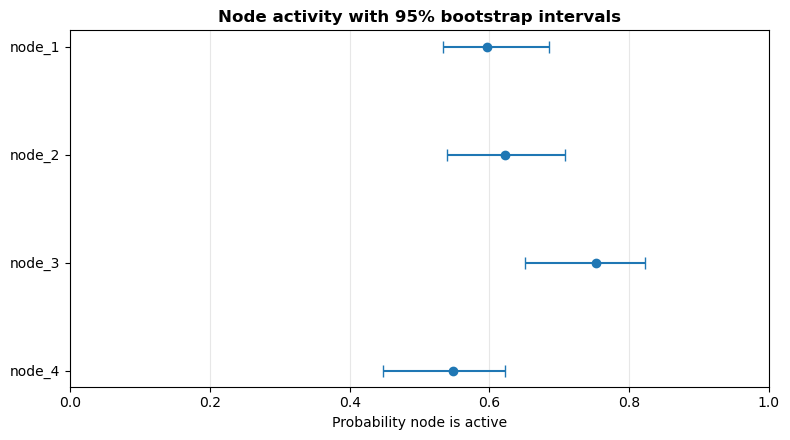

In [33]:
import matplotlib.pyplot as plt

def plot_activity_uncertainty(summary):
    d = summary.dropna(subset=["estimate", "lower", "upper"]).copy()
    d = d.sort_values("node", ascending=False).reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    y = np.arange(len(d))
    ax.errorbar(d["estimate"], y, xerr=np.vstack([d["estimate"] - d["lower"], d["upper"] - d["estimate"],]), fmt="o", capsize=4,)
    ax.set_yticks(y, d["node"])
    ax.set_xlim(0, 1)
    ax.set_xlabel("Probability node is active")
    ax.set_title("Node activity with 95% bootstrap intervals", weight='bold')
    ax.grid(axis="x", alpha=0.3)
    fig.tight_layout()
    return fig, ax

plot_activity_uncertainty(df_activity)
plt.show()

In [34]:
df_rates

,node,transition_type,estimate,bootstrap_se,lower,upper,valid_replicates,n_bootstrap
0,node_1,0_to_1,1.274713,0.160804,1.020534,1.634558,1000,1000
1,node_1,1_to_0,0.880304,0.111394,0.649997,1.085240,1000,1000
2,node_2,0_to_1,1.152987,0.174285,0.893800,1.596733,1000,1000
3,node_2,1_to_0,0.700210,0.094699,0.546185,0.919021,1000,1000
4,node_3,0_to_1,1.556394,0.243286,1.122756,2.069027,1000,1000
5,node_3,1_to_0,0.513549,0.095777,0.358561,0.737517,1000,1000
6,node_4,0_to_1,1.030384,0.146005,0.777817,1.371623,1000,1000
7,node_4,1_to_0,0.848591,0.126723,0.676162,1.157113,1000,1000


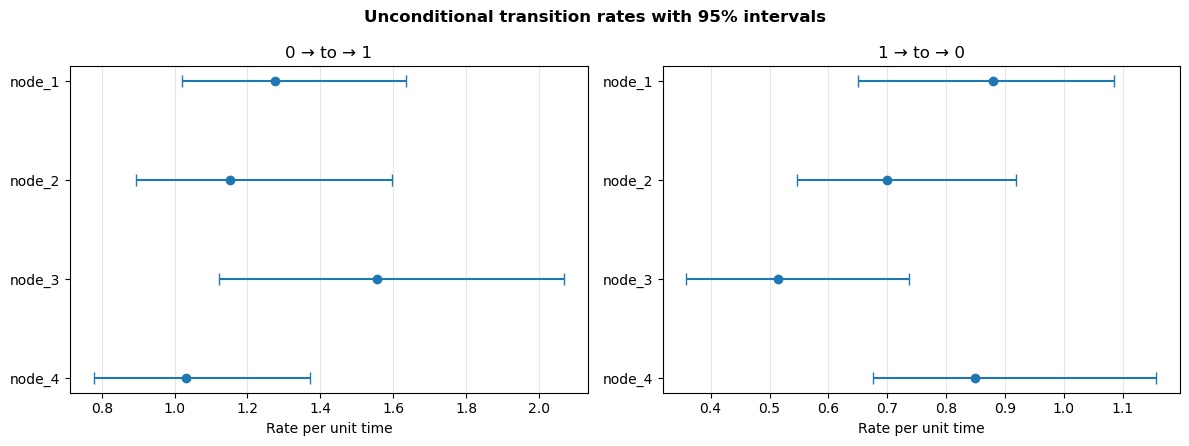

In [35]:
def plot_transition_uncertainty(summary):
    d = summary.dropna(subset=["estimate", "lower", "upper"]).copy()
    directions = ["0_to_1", "1_to_0"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, direction in zip(axes, directions):
        sub = d.loc[d["transition_type"] == direction]
        sub = sub.sort_values("node", ascending=False).reset_index(drop=True)
        y = np.arange(len(sub))
        ax.errorbar(sub["estimate"], y, xerr=np.vstack([sub["estimate"] - sub["lower"], sub["upper"] - sub["estimate"],]), fmt="o", capsize=4,)
        ax.set_yticks(y, sub["node"])
        ax.set_xlabel("Rate per unit time")
        ax.set_title(direction.replace("_", " → "))
        ax.grid(axis="x", alpha=0.3)
    fig.suptitle("Unconditional transition rates with 95% intervals", weight='bold')
    fig.tight_layout()
    return fig, axes

plot_transition_uncertainty(df_rates)
plt.show()

In [36]:
df_conditional.head()

,target,context,context_state,transition_type,estimate,bootstrap_se,lower,upper,valid_replicates,n_bootstrap
0,node_1,node_2,0.0,0_to_1,0.830880,0.190896,0.425536,1.170666,1000,1000
1,node_1,node_2,0.0,1_to_0,1.307667,0.313190,0.736505,1.956215,1000,1000
2,node_1,node_2,1.0,0_to_1,0.883790,0.117053,0.689765,1.139205,1000,1000
3,node_1,node_2,1.0,1_to_0,1.294164,0.211387,0.967699,1.770095,1000,1000
4,node_1,node_3,0.0,0_to_1,1.112654,0.265074,0.665442,1.758029,1000,1000


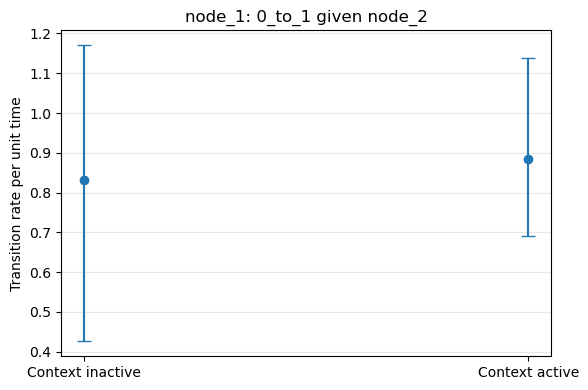

In [37]:
def plot_conditional_rates(summary, target, context, transition_type="0_to_1",):
    d = summary.loc[
        (summary["target"] == target)
        & (summary["context"] == context)
        & (summary["transition_type"] == transition_type)
    ].copy()
    d = d.dropna(subset=["estimate", "lower", "upper"])
    d = d.sort_values(["target"], ascending=False).reset_index(drop=True)
    if d.empty:
        raise ValueError("No valid conditional estimates to plot.")
    fig, ax = plt.subplots(figsize=(6, 4))
    x = d["context_state"].to_numpy()
    est = d["estimate"].to_numpy()
    ax.errorbar(x, est, yerr=np.vstack([est - d["lower"].to_numpy(), d["upper"].to_numpy() - est,]), fmt="o", capsize=5,)
    ax.set_xticks([0, 1], ["Context inactive", "Context active"])
    ax.set_ylabel("Transition rate per unit time")
    ax.set_title(f"{target}: {transition_type} given {context}")
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    return fig, ax
plot_conditional_rates(df_conditional, target="node_1", context="node_2", transition_type="0_to_1",)
plt.show()

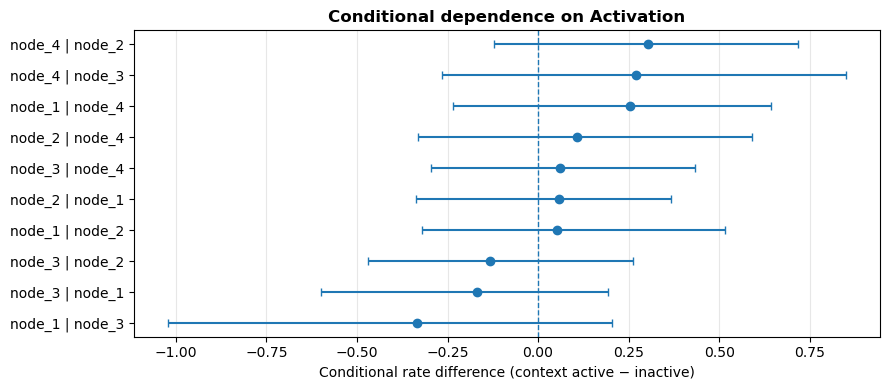

In [ ]:
def plot_rate_differences(differences, transition_type="0_to_1", top_n=10):
    """ Plots top 10 most extreme context differences between nodes based on activation timeline """
    d = differences.loc[differences["transition_type"] == transition_type].dropna(subset=["rate_difference", "lower", "upper"]).copy()
    d = d.loc[d["rate_difference"].abs().nlargest(top_n).index].sort_values("rate_difference", ascending=True).reset_index(drop=True)

    if d.empty:
        raise ValueError("No valid rate differences to plot.")
    labels = d["target"] + " | " + d["context"]
    y = np.arange(len(d))
    est = d["rate_difference"].to_numpy()
    fig, ax = plt.subplots(figsize=(9, max(4, 0.35 * len(d))))
    ax.errorbar(est, y, xerr=np.vstack([est - d["lower"].to_numpy(), d["upper"].to_numpy() - est,]), fmt="o", capsize=3,)
    ax.axvline(0, linestyle="--", linewidth=1)
    ax.set_yticks(y, labels)
    ax.set_xlabel("Conditional rate difference (context active − inactive)")
    ax.set_title(f"Conditional dependence on Activation", weight='bold')
    ax.grid(axis="x", alpha=0.3)
    fig.tight_layout()
    return fig, ax

differences = uncertainty.conditional_rate_differences()
plot_rate_differences(differences, "0_to_1")
plt.show()